In [1]:
# Should understand this code at some point
from pathlib import Path
import sys

project_root = Path.cwd().parent  # notebook is in Notebooks/
sys.path.insert(0, str(project_root / "src"))

import mnist_loader
import neural_network_nielsen
import image_processing
import numpy as np

In [ ]:
# Load in all of the data
data = mnist_loader.load_data_wrapper()

In [16]:
# Initialise out neural network
net = neural_network_nielsen.Network(sizes=[784,16,16,10])

In [3]:
# Get Centred Training Data and Validation Data
training_data = data[0]
validation_data = data[1]
training_data = image_processing.centre_dataset(dataset=training_data, side_length=28)
validation_data = image_processing.centre_dataset(dataset=validation_data, side_length=28)


In [14]:
# Store the hyperparameters in one cell so can keep track
epochs=50
mini_batch_size=10
eta=1.0

In [17]:
# Run Stochastic Gradient Descent on our Network
neural_network_nielsen.Network.SGD(net, training_data, epochs=epochs, mini_batch_size=mini_batch_size, eta=eta, test_data=validation_data)

Starting Epoch 0...
Epoch 0: Test Loss is [[0.23073965]], Test Accuracy is 0.8515
Starting Epoch 1...
Epoch 1: Test Loss is [[0.17312887]], Test Accuracy is 0.8913
Starting Epoch 2...
Epoch 2: Test Loss is [[0.14518608]], Test Accuracy is 0.9071
Starting Epoch 3...
Epoch 3: Test Loss is [[0.13049092]], Test Accuracy is 0.9191
Starting Epoch 4...
Epoch 4: Test Loss is [[0.13209066]], Test Accuracy is 0.9176
Starting Epoch 5...
Epoch 5: Test Loss is [[0.12503155]], Test Accuracy is 0.9209
Starting Epoch 6...
Epoch 6: Test Loss is [[0.11727003]], Test Accuracy is 0.9256
Starting Epoch 7...
Epoch 7: Test Loss is [[0.11532654]], Test Accuracy is 0.928
Starting Epoch 8...
Epoch 8: Test Loss is [[0.11613027]], Test Accuracy is 0.9271
Starting Epoch 9...
Epoch 9: Test Loss is [[0.11641845]], Test Accuracy is 0.9269
Starting Epoch 10...
Epoch 10: Test Loss is [[0.11126193]], Test Accuracy is 0.9308
Starting Epoch 11...
Epoch 11: Test Loss is [[0.11404069]], Test Accuracy is 0.9306
Starting Epoc

In [61]:
file_path = Path.cwd().parent / "data" / "processed" / "centred_trained_network.npz"
neural_network_nielsen.Network.save(net, filename=file_path)

In [62]:
# Instead of running SGD all over again we simply load in the saved trained weights and biases
file_path = Path.cwd().parent / "data" / "processed" / "centred_trained_network.npz"
net.load(filename=file_path)

In [63]:
# Look at the accuracy of trained net on unseen data
accuracy = neural_network_nielsen.Network.evaluate(net, validation_data)
print(accuracy)

0.9399


In [64]:
# Get the confusion matrix for the validation data and see which digits perform best
confusion_matrix = neural_network_nielsen.Network.confusion_matrix(net, validation_data)
print(confusion_matrix)

[[9.630e+02 0.000e+00 4.000e+00 1.000e+00 0.000e+00 3.000e+00 4.000e+00
  3.000e+00 1.300e+01 0.000e+00]
 [0.000e+00 1.041e+03 4.000e+00 4.000e+00 2.000e+00 2.000e+00 3.000e+00
  3.000e+00 5.000e+00 0.000e+00]
 [5.000e+00 3.000e+00 9.130e+02 1.000e+01 1.000e+01 3.000e+00 8.000e+00
  1.100e+01 2.500e+01 2.000e+00]
 [2.000e+00 4.000e+00 1.600e+01 9.530e+02 0.000e+00 2.200e+01 2.000e+00
  9.000e+00 1.700e+01 5.000e+00]
 [2.000e+00 3.000e+00 3.000e+00 1.000e+00 9.350e+02 5.000e+00 1.000e+00
  4.000e+00 8.000e+00 2.100e+01]
 [8.000e+00 3.000e+00 6.000e+00 3.000e+01 3.000e+00 8.240e+02 1.700e+01
  3.000e+00 1.200e+01 9.000e+00]
 [7.000e+00 1.000e+00 7.000e+00 1.000e+00 7.000e+00 3.000e+00 9.340e+02
  0.000e+00 7.000e+00 0.000e+00]
 [7.000e+00 8.000e+00 4.000e+00 8.000e+00 8.000e+00 0.000e+00 0.000e+00
  1.032e+03 4.000e+00 1.900e+01]
 [7.000e+00 6.000e+00 1.200e+01 1.800e+01 4.000e+00 1.500e+01 6.000e+00
  6.000e+00 9.240e+02 1.100e+01]
 [5.000e+00 1.000e+00 0.000e+00 9.000e+00 2.700e+01 9.0

In [66]:
# Finding out how well the network identifies true labels of different digits and whether there are huge differences
recalls = [confusion_matrix[i,i]/np.sum(confusion_matrix[i]) for i in range(10)]
precisions = [confusion_matrix[i,i]/np.sum(confusion_matrix[:,i]) for i in range(10)]
total_predictions = confusion_matrix.sum(axis=0)
total_labels = confusion_matrix.sum(axis=1)
print(recalls)
print(precisions)
print(total_predictions)
print(total_labels)


[np.float64(0.9717457114026236), np.float64(0.9783834586466166), np.float64(0.9222222222222223), np.float64(0.925242718446602), np.float64(0.9511698880976602), np.float64(0.9005464480874317), np.float64(0.9658738366080661), np.float64(0.9467889908256881), np.float64(0.9157581764122894), np.float64(0.9157127991675338)]
[np.float64(0.9572564612326043), np.float64(0.9728971962616823), np.float64(0.9422084623323014), np.float64(0.9207729468599034), np.float64(0.9387550200803213), np.float64(0.9300225733634312), np.float64(0.9569672131147541), np.float64(0.945054945054945), np.float64(0.9032258064516129), np.float64(0.9292502639915523)]
[1006. 1070.  969. 1035.  996.  886.  976. 1092. 1023.  947.]
[ 991. 1064.  990. 1030.  983.  915.  967. 1090. 1009.  961.]


In [58]:
# 1. Get the absolute path of the directory containing script.py (the 'src' folder)
NOTEBOOK_DIR = Path.cwd()

# 2. Go up one level to the root, then down into 'data'
# Comparing a folder of high sevens to a folder of low sevens
FOLDER = NOTEBOOK_DIR.parent / "data" / "raw" / "better_wacom_digits" / "9"

In [59]:
stylus_data = image_processing.load_digit_folder(FOLDER)

In [60]:
centred_stylus_data = image_processing.centre_dataset(dataset=stylus_data, side_length=28)
accuracy = neural_network_nielsen.Network.evaluate(net, test_data=centred_stylus_data)
print(f"The accuracy of the new network trained on centred examples on centred validation data is {accuracy}.")


The accuracy of the new network trained on centred examples on centred validation data is 1.0.


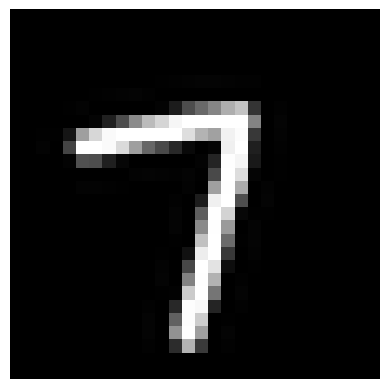

In [23]:
import matplotlib.pyplot as plt
example = centred_stylus_data[0]
x, y = example
plt.imshow(x.reshape(28, 28), cmap="gray")
plt.axis("off")
plt.show()

In [ ]:
shifted_example = image_processing.translate_data(
    centred_stylus_data, vertical_shift=11, horizontal_shift=0, side_length=28
)
plt.imshow(shifted_example[0].reshape(28, 28), cmap="gray")
plt.axis("off")
plt.show()


In [24]:
import numpy as np
# Evaluate the guess for data x and the corresponding confidence of that guess
output = neural_network_nielsen.Network.feedforward(net, x)
guess = np.argmax(output)
confidence = np.max(output)/np.sum(output)
print(f"The guess for the above image is {guess} with a {confidence} level of confidence.")

The guess for the above image is 7 with a 0.9943869484361997 level of confidence.


In [26]:
def shift_eval(net, dataset, shift_limit, side_length=28):
    accuracies = []
    for shift in range(shift_limit + 1):
        new_set = image_processing.translate_dataset(
            dataset, vertical_shift=-shift, horizontal_shift=0, side_length=side_length
        )
        accuracy = neural_network_nielsen.Network.evaluate(net, test_data=new_set)
        accuracies.append(accuracy)
    return accuracies


In [28]:
# Test new function on stylus data which is currently the low seven data (expect high accuracies for low shifts and low accuracy for high shifts)
accuracies = shift_eval(net=net, dataset=stylus_data, shift_limit=28, side_length=28)
print(accuracies)

[np.float64(0.8461538461538461), np.float64(0.8461538461538461), np.float64(0.8461538461538461), np.float64(0.7692307692307693), np.float64(0.5384615384615384), np.float64(0.46153846153846156), np.float64(0.15384615384615385), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.07692307692307693), np.float64(0.07692307692307693), np.float64(0.15384615384615385), np.float64(0.15384615384615385), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.07692307692307693), np.float64(0.07692307692307693), np.float64(0.3076923076923077), np.float64(0.38461538461538464), np.float64(0.46153846153846156), np.float64(0.8461538461538461)]
